# Phase contrast → cell cycle phase: exploring the prediction and its QC

Explore the output of `scripts/ops0077_phase_predict_cc_phase.py`.

- `cc_phase`: the label, derived from markers + DNA content (circular, [0, 1))
- `pred_phase`: predicted from phase-contrast features only
- `error_turns`: circular error, `((pred - true + 0.5) % 1) - 0.5`, in turns (0.5 = the opposite side of the cycle)

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
ROOT = Path("..") if Path("../reports").exists() else Path(".")
REP = ROOT / "reports/ops0077_phase_predicts_cc_phase"
pred = pd.read_csv(REP / "phase_predicted_cc_phase.csv", index_col=0)
summary = json.load(open(REP / "summary.json"))
feat_imp = pd.read_csv(REP / "feature_importance.csv")
scores = pd.read_csv(ROOT / "reports/ops0077_cell_cycle_score/cell_cycle_scores.csv", index_col=0).drop_duplicates("cell_key", keep=False).set_index("cell_key")
oof = pred[pred["pred_is_out_of_fold"]].copy()
oof["abs_err"] = oof["error_turns"].abs()
print(summary["best_model"], summary["feature_groups"], len(oof), "out-of-fold cells")
pred.head()

ridge {'organelle_focus3d': 759, 'organelle_phase2d': 765} 35633 out-of-fold cells


,well,tile_pheno,pheno_to_fixed_distance_px,cells_in_tile,cc_phase,cc_phase_source,cc_curve_dist_dna,z_dna,z_p21,z_phos,...,pred_sin_ridge,pred_cos_ridge,pred_sin_hgb_pca,pred_cos_hgb_pca,pred_sin,pred_cos,pred_phase,pred_confidence,pred_is_out_of_fold,error_turns
A/1/0|18387235,A/1/0,A/1/019026,25.703632,8,NaN,NaN,NaN,NaN,4.000000,-0.821184,...,NaN,NaN,NaN,NaN,-0.908924,-1.104896,0.609561,1.430712,False,NaN
A/1/0|11020659,A/1/0,A/1/022016,22.721680,9,NaN,NaN,NaN,NaN,1.520478,-0.103395,...,NaN,NaN,NaN,NaN,0.124237,0.857829,0.022891,0.866778,False,NaN
A/1/0|28741398,A/1/0,A/1/017040,58.061310,5,NaN,NaN,NaN,NaN,1.480917,-0.949212,...,NaN,NaN,NaN,NaN,0.633928,0.436384,0.154048,0.769607,False,NaN
A/1/0|17042695,A/1/0,A/1/026022,6.864303,17,NaN,NaN,NaN,NaN,0.469072,1.087273,...,NaN,NaN,NaN,NaN,-0.461886,-0.753421,0.587529,0.883732,False,NaN
A/1/0|17590749,A/1/0,A/1/045024,23.708580,11,NaN,NaN,NaN,NaN,0.895583,0.841961,...,NaN,NaN,NaN,NaN,0.713212,0.576880,0.141757,0.917312,False,NaN


## 1. Headline performance and baselines

In [2]:
tab = pd.DataFrame(summary["results"]).T
display(tab[["n", "mae_turns", "median_abs_err", "within_0p10", "acc_4bins", "acc_8bins", "circ_agreement"]].round(3))
# a random guess has MAE 0.25, within_0p10 0.20, acc_4bins 0.25, acc_8bins 0.125

,n,mae_turns,median_abs_err,within_0p10,acc_4bins,acc_8bins,circ_agreement
ridge|tile_cv,35633.0,0.105,0.072,0.629,0.617,0.432,0.689
ridge|leave_one_well_out,35633.0,0.113,0.077,0.598,0.597,0.401,0.654
hgb_pca|tile_cv,35633.0,0.124,0.083,0.568,0.575,0.392,0.602
hgb_pca|leave_one_well_out,35633.0,0.130,0.088,0.545,0.557,0.368,0.577
baseline_size_only|tile_cv,35633.0,0.174,0.124,0.420,0.490,0.291,0.372
baseline_context_only|tile_cv,35633.0,0.188,0.134,0.410,0.445,0.278,0.300
random_guess,NaN,0.250,NaN,0.200,0.250,0.125,NaN
ridge_op_only|cp_subset,8341.0,0.090,0.060,0.709,0.676,0.498,0.754
ridge_op_plus_cp|cp_subset,8341.0,0.091,0.061,0.706,0.673,0.494,0.748


## 2. Predicted vs true

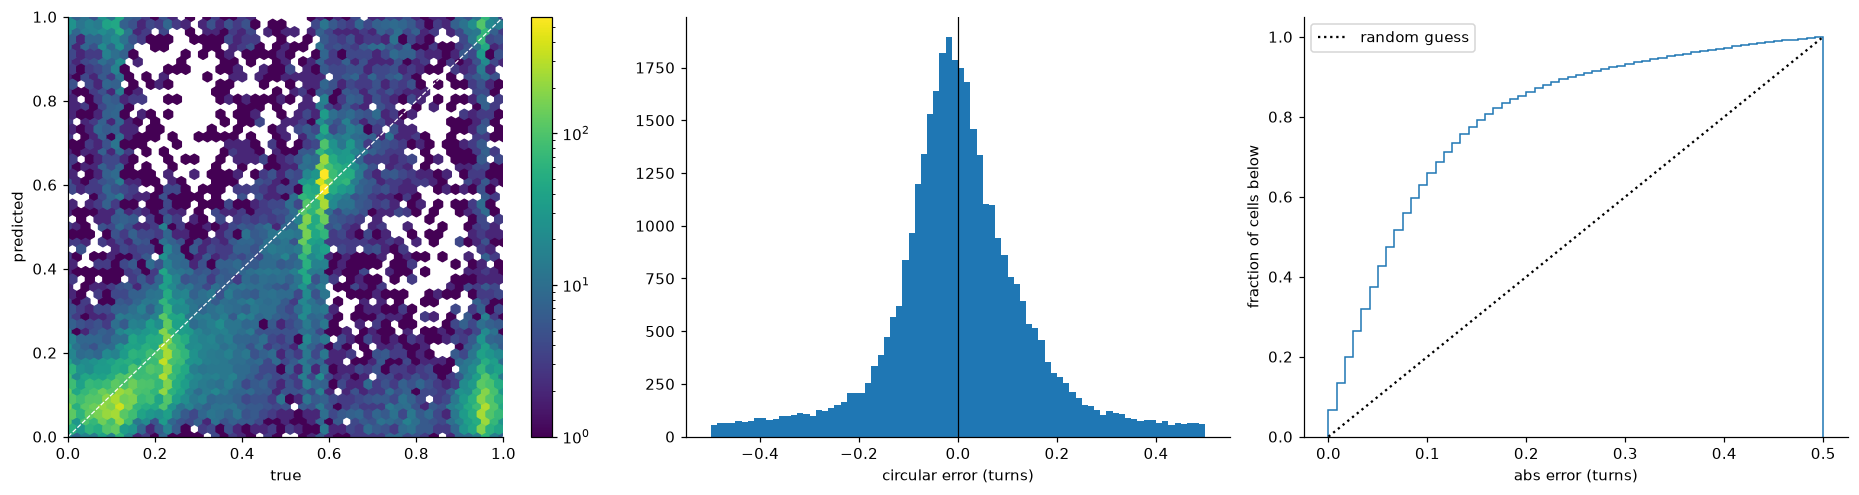

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
h = ax[0].hexbin(oof["cc_phase"], oof["pred_phase"], gridsize=50, cmap="viridis", mincnt=1, bins="log")
for off in (-1, 0, 1): ax[0].plot([0, 1], [off, 1 + off], "w--", lw=.8)
ax[0].set_xlim(0, 1); ax[0].set_ylim(0, 1); ax[0].set_xlabel("true"); ax[0].set_ylabel("predicted"); plt.colorbar(h, ax=ax[0])
ax[1].hist(oof["error_turns"], bins=80); ax[1].axvline(0, c="k", lw=.8); ax[1].set_xlabel("circular error (turns)")
ax[2].hist(oof["abs_err"], bins=60, cumulative=True, density=True, histtype="step")
ax[2].plot([0, .5], [0, 1], "k:", label="random guess"); ax[2].legend(); ax[2].set_xlabel("abs error (turns)"); ax[2].set_ylabel("fraction of cells below")
plt.tight_layout()

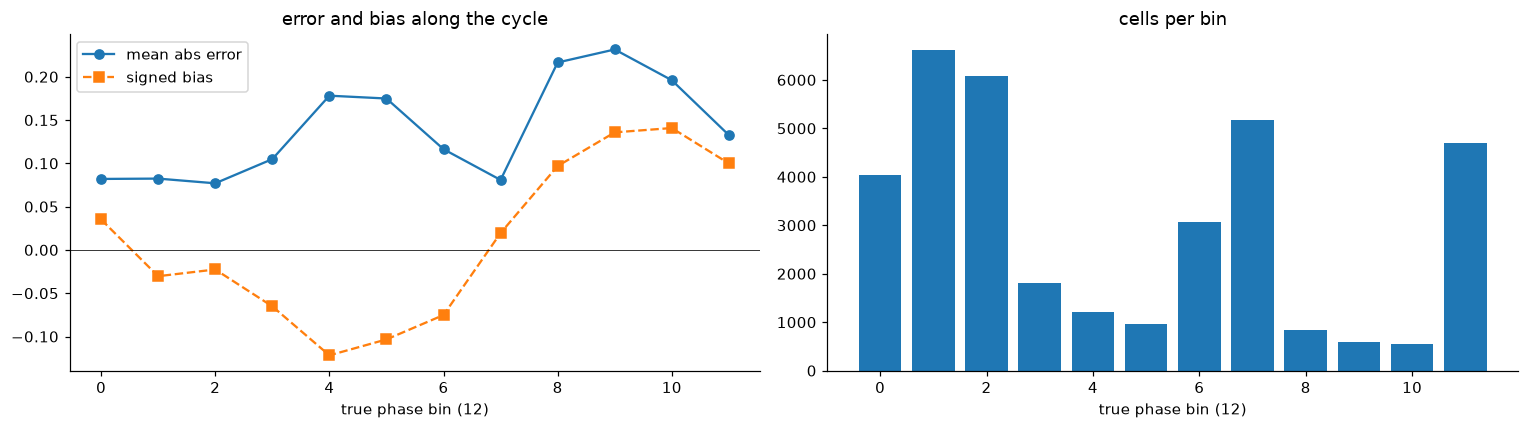

In [4]:
# error along the cycle: which phases are easy / hard?
oof["true_bin"] = pd.cut(oof["cc_phase"], np.linspace(0, 1, 13), include_lowest=True)
g = oof.groupby("true_bin", observed=True)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(range(len(g)), g["abs_err"].mean(), "o-", label="mean abs error"); ax[0].plot(range(len(g)), g["error_turns"].mean(), "s--", label="signed bias")
ax[0].axhline(0, c="k", lw=.5); ax[0].set_xlabel("true phase bin (12)"); ax[0].legend(); ax[0].set_title("error and bias along the cycle")
ax[1].bar(range(len(g)), g.size()); ax[1].set_xlabel("true phase bin (12)"); ax[1].set_title("cells per bin")
plt.tight_layout()

A positive signed bias means the model predicts too far forward in the cycle for that bin, and a negative bias too far back. Regression towards the middle of the cycle often shows up at the G1/G2 ends of the loop.

## 3. Confusion and calibration

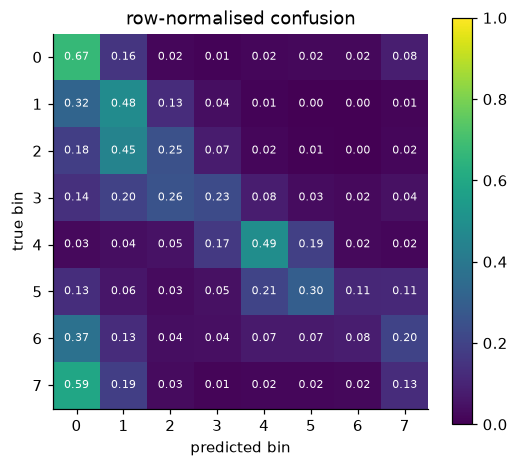

In [5]:
nb = 8
tb = np.floor(oof["cc_phase"] * nb).astype(int) % nb; pb = np.floor(oof["pred_phase"] * nb).astype(int) % nb
cm = pd.crosstab(tb, pb, normalize="index").reindex(index=range(nb), columns=range(nb), fill_value=0)
plt.figure(figsize=(5.5, 4.8)); plt.imshow(cm.values, cmap="viridis", vmin=0, vmax=1); plt.colorbar()
plt.xlabel("predicted bin"); plt.ylabel("true bin"); plt.title("row-normalised confusion")
for i in range(nb):
    for j in range(nb): plt.text(j, i, f"{cm.values[i, j]:.2f}", ha="center", va="center", color="w", fontsize=7)

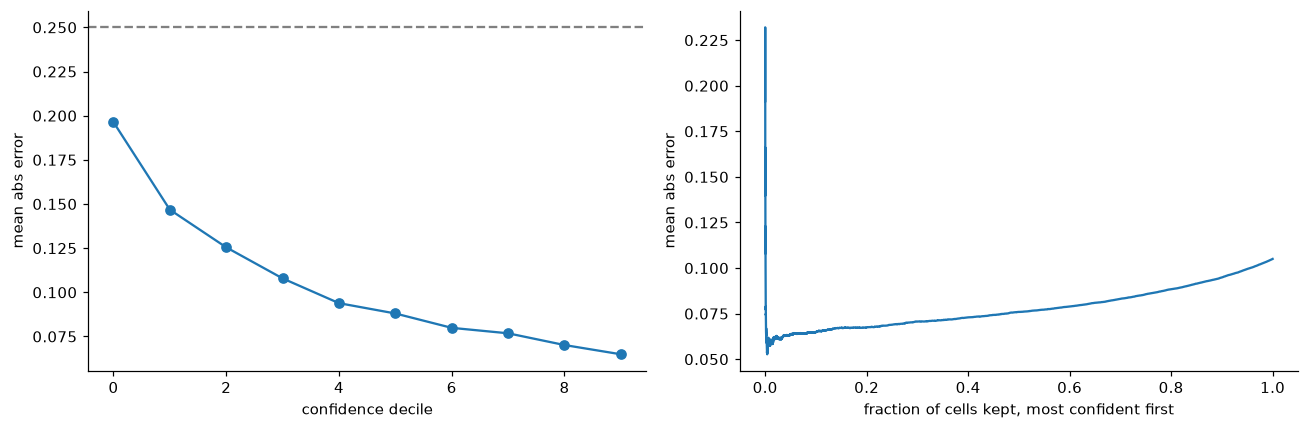

In [6]:
# is the confidence (length of the predicted sin/cos vector) informative?
oof["conf_dec"] = pd.qcut(oof["pred_confidence"], 10, duplicates="drop")
g = oof.groupby("conf_dec", observed=True)["abs_err"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(len(g)), g.mean(), "o-"); ax[0].axhline(.25, c="gray", ls="--"); ax[0].set_xlabel("confidence decile"); ax[0].set_ylabel("mean abs error")
order = np.argsort(-oof["pred_confidence"].values); cum = np.cumsum(oof["abs_err"].values[order]) / np.arange(1, len(order) + 1)
ax[1].plot(np.arange(1, len(order) + 1) / len(order), cum); ax[1].set_xlabel("fraction of cells kept, most confident first"); ax[1].set_ylabel("mean abs error")
plt.tight_layout()

## 4. What drives the error? Registration distance, well, tile density, label quality

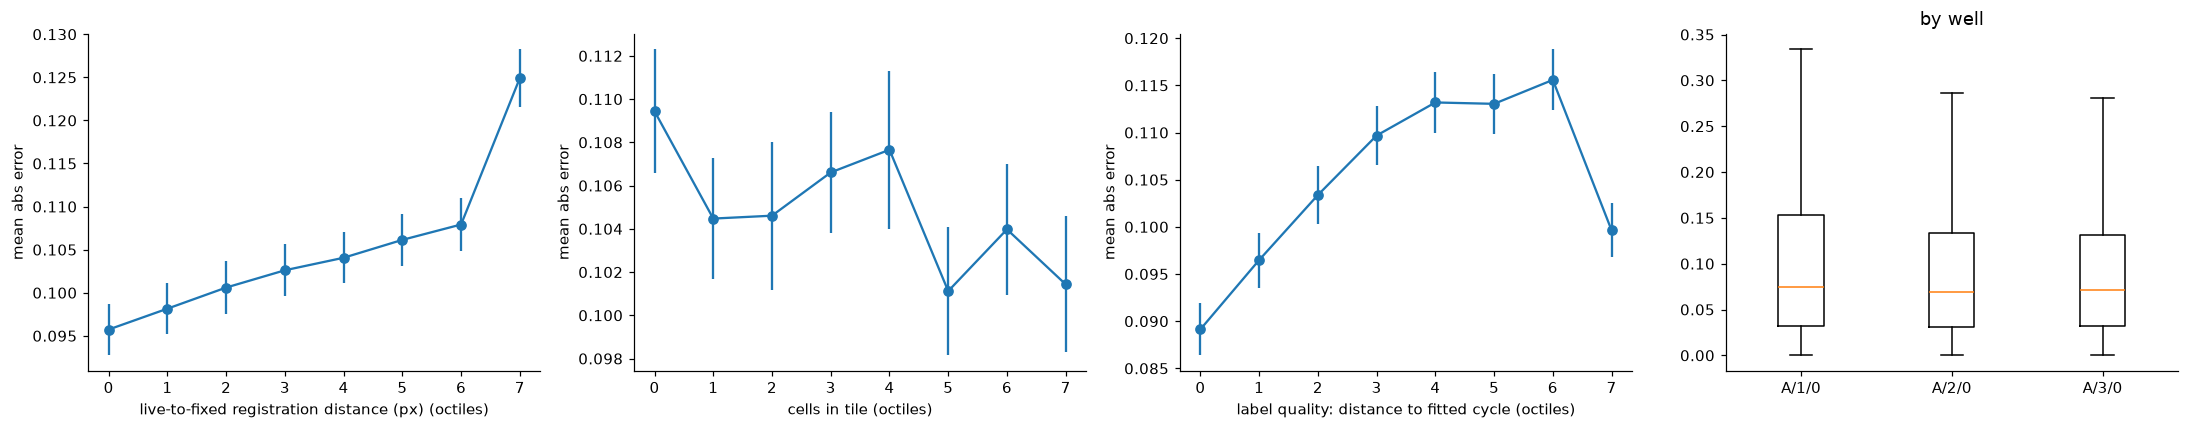

In [7]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for a, (col, nm) in zip(ax, [("pheno_to_fixed_distance_px", "live-to-fixed registration distance (px)"), ("cells_in_tile", "cells in tile"),
                              ("cc_curve_dist_dna", "label quality: distance to fitted cycle")]):
    q = pd.qcut(oof[col], 8, duplicates="drop"); g = oof.groupby(q, observed=True)["abs_err"].agg(["mean", "sem"])
    a.errorbar(range(len(g)), g["mean"], g["sem"] * 1.96, fmt="o-"); a.set_xlabel(nm + " (octiles)"); a.set_ylabel("mean abs error")
ax[3].boxplot([oof.loc[oof["well"] == w, "abs_err"] for w in sorted(oof["well"].unique())], showfliers=False)
ax[3].set_xticklabels(sorted(oof["well"].unique())); ax[3].set_title("by well")
plt.tight_layout()

In [8]:
# how much does a registration-distance cut help, and at what cost in coverage?
rows = []
for t in [10, 20, 30, 40, 60, 80, 120]:
    m = oof["pheno_to_fixed_distance_px"] <= t
    rows.append(dict(max_distance_px=t, cells=int(m.sum()), fraction_kept=m.mean(), mae=oof.loc[m, "abs_err"].mean(),
                     within_0p10=(oof.loc[m, "abs_err"] <= 0.10).mean()))
pd.DataFrame(rows).round(3)

,max_distance_px,cells,fraction_kept,mae,within_0p10
0,10,1876,0.053,0.095,0.687
1,20,8563,0.240,0.097,0.672
2,30,16848,0.473,0.099,0.661
3,40,24783,0.696,0.101,0.649
4,60,33556,0.942,0.103,0.636
5,80,35170,0.987,0.104,0.631
6,120,35615,0.999,0.105,0.629


A clear drop in error with smaller registration distance means part of the "error" is real cell cycle progression, or a wrong cell match, between live imaging and fixation: the label belongs to the fixed cell, the features to the live one. The script option `--max-reg-dist` restricts training and evaluation to well-matched cells.

## 5. Does the prediction recover the biology?
Median marker and DNA profiles along the true phase and along the predicted phase should look alike.

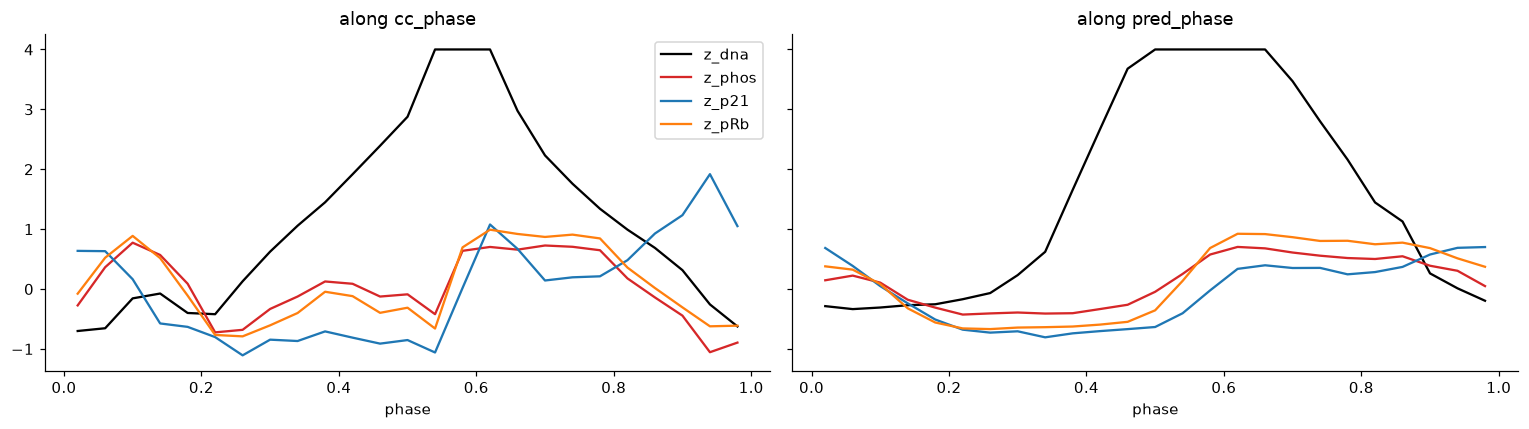

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for a, col in zip(ax, ["cc_phase", "pred_phase"]):
    b = pd.cut(oof[col], np.linspace(0, 1, 26)); mid = np.linspace(0, 1, 26)[:-1] + 0.02
    for f, c in [("z_dna", "k"), ("z_phos", "C3"), ("z_p21", "C0"), ("z_pRb", "C1")]:
        gm = oof.groupby(b, observed=True)[f].median(); a.plot(mid[:len(gm)], gm.values, c=c, label=f)
    a.set_title(f"along {col}"); a.set_xlabel("phase")
ax[0].legend(); plt.tight_layout()

## 6. Phase contrast vs markers-only
The markers-only phase (`cc_phase_markers`, no DNA) was a weak predictor of the DNA-anchored phase. How does phase contrast compare on the same cells?

In [10]:
def cdiff(a, b): return (a - b + 0.5) % 1.0 - 0.5
m = oof.join(scores[["cc_phase_markers"]]).dropna(subset=["cc_phase_markers"])
r = pd.DataFrame({"markers only (no DNA)": cdiff(m["cc_phase_markers"], m["cc_phase"]).abs(),
                  "phase contrast": m["abs_err"]}).describe().loc[["count", "mean", "50%"]]
display(r.round(3))

,markers only (no DNA),phase contrast
count,35633.000,35633.000
mean,0.301,0.105
50%,0.334,0.072


## 7. Cells without a label

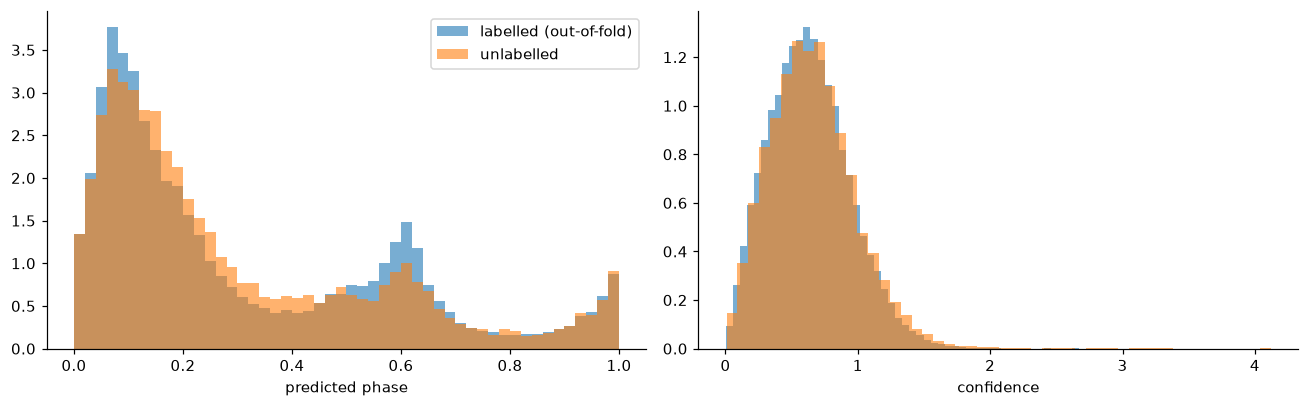

In [11]:
# predictions for cells with no reliable DNA measurement: is the distribution similar to the labelled cells?
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(pred.loc[pred["pred_is_out_of_fold"], "pred_phase"], bins=50, density=True, alpha=.6, label="labelled (out-of-fold)")
ax[0].hist(pred.loc[~pred["pred_is_out_of_fold"], "pred_phase"], bins=50, density=True, alpha=.6, label="unlabelled")
ax[0].legend(); ax[0].set_xlabel("predicted phase")
ax[1].hist(pred.loc[pred["pred_is_out_of_fold"], "pred_confidence"], bins=50, density=True, alpha=.6)
ax[1].hist(pred.loc[~pred["pred_is_out_of_fold"], "pred_confidence"], bins=50, density=True, alpha=.6); ax[1].set_xlabel("confidence")
plt.tight_layout()

The unlabelled cells are not a random sample: they lack a reliable DNA measurement and tend to be worse registered, so their predictions are expected to be less reliable. Use `pred_confidence` and the registration distance to filter.

## 8. Which features carry the signal?

In [12]:
print(feat_imp.groupby("group")[["harmonic_r2_phase", "ridge_importance"]].agg(["mean", "max"]).round(4))
feat_imp.sort_values("harmonic_r2_phase", ascending=False).head(25)[["feature", "group", "harmonic_r2_phase", "ridge_importance"]]

                  harmonic_r2_phase         ridge_importance        
                               mean     max             mean     max
group                                                               
organelle_focus3d              -inf  0.2741           0.0491  0.6396
organelle_phase2d              -inf  0.2639           0.0406  0.3913


,feature,group,harmonic_r2_phase,ridge_importance
0,op_nucleoli_focus3d_intensity_mean_max,organelle_focus3d,0.274091,0.042956
1,op_nucleoli_focus3d_intensity_max_max,organelle_focus3d,0.270789,0.039603
2,op_focus3d_vesicular_intensity_min_std,organelle_focus3d,0.268094,0.126959
3,op_focus3d_tubular_intensity_min_max,organelle_focus3d,0.264726,0.017805
4,op_phase2d_tubular_intensity_min_max,organelle_phase2d,0.263925,0.023992
5,op_focus3d_vesicular_intensity_mean_std,organelle_focus3d,0.260195,0.079719
6,op_phase2d_vesicular_intensity_min_max,organelle_phase2d,0.259578,0.008885
7,op_nucleoli_phase2d_intensity_mean_max,organelle_phase2d,0.254261,0.024389
8,op_focus3d_tubular_intensity_mean_max,organelle_focus3d,0.252694,0.028104
9,op_phase2d_tubular_intensity_mean_max,organelle_phase2d,0.252512,0.042173


In [13]:
abl_path = REP / "ablation_by_group.csv"
if abl_path.exists():
    abl = pd.read_csv(abl_path); display(abl.pivot(index="group", columns="mode", values="mae_turns").round(3))
    # 'only' = that group alone, 'without' = everything except that group (ridge, 3-fold tile CV on a subsample)

mode,only,without
group,,
organelle_focus3d,0.108,0.114
organelle_phase2d,0.114,0.108


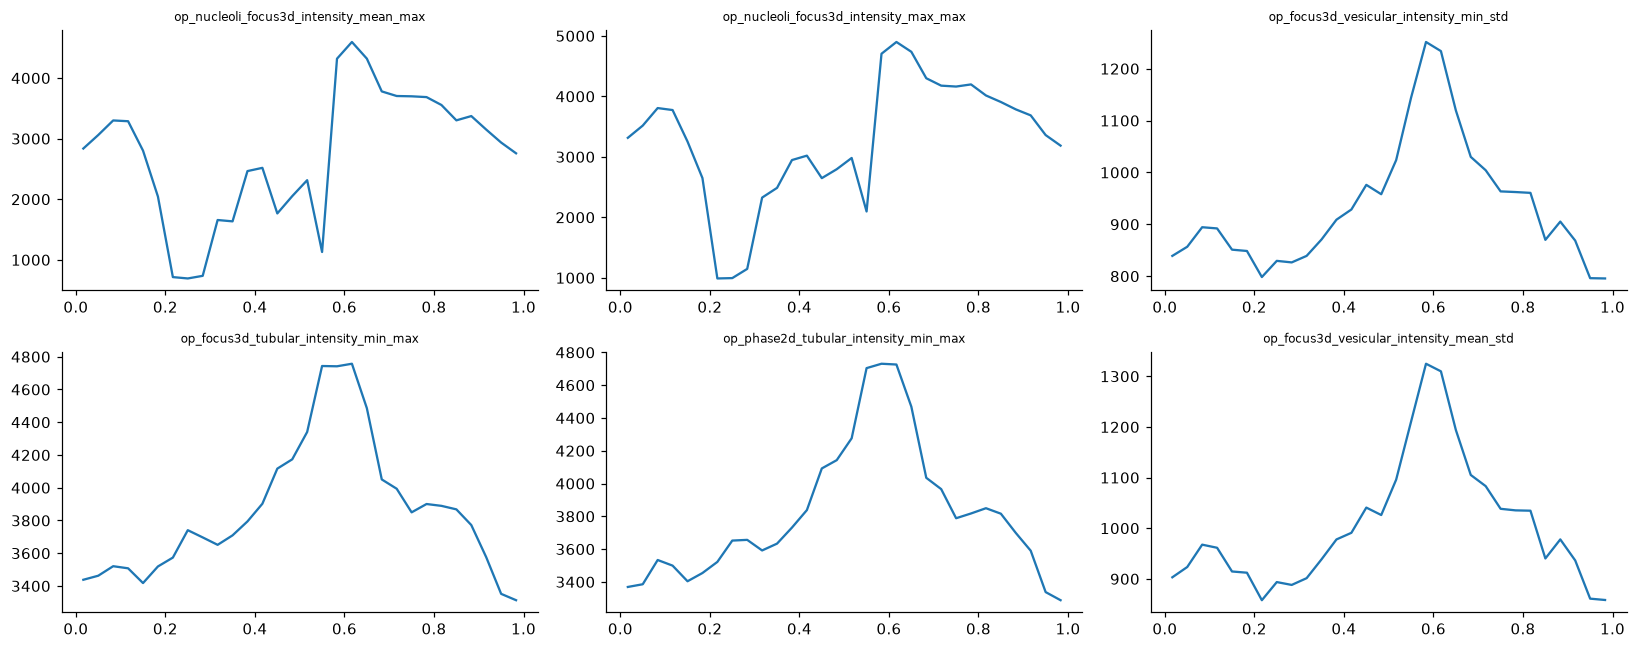

In [14]:
# the strongest single features around the cycle (median per phase bin, on the true phase)
import anndata as ad
a = ad.read_h5ad(ROOT / "data/altair/OPS0077_NTC_phase_OrganelleProfiler.h5ad")
a.obs_names = a.obs["cell_key"].values
top = feat_imp.sort_values("harmonic_r2_phase", ascending=False)["feature"].head(6).tolist()
Xd = pd.DataFrame(np.asarray(a[:, top].X, float), index=a.obs_names, columns=top).join(oof["cc_phase"], how="inner")
fig, ax = plt.subplots(2, 3, figsize=(15, 6))
for axx, f in zip(ax.ravel(), top):
    g = Xd.groupby(pd.cut(Xd["cc_phase"], np.linspace(0, 1, 31)), observed=True)[f].median()
    axx.plot(np.linspace(0, 1, 31)[:-1][:len(g)] + 1 / 60, g.values); axx.set_title(f[-45:], fontsize=8)
plt.tight_layout()